## What is a Transformer?

A **Transformer** is a neural-network architecture that uses **attention** to process sequences. It is widely used in language models, translation, summarization, question answering, and text classification.

Unlike an RNN, which processes tokens sequentially, a Transformer can compare tokens with one another through attention and process positions in parallel during training.

### Core idea: self-attention

Self-attention lets each token representation use information from other tokens in the same sequence.

For example, in “The animal was tired because it ran,” the representation of “it” may learn to use information from other words in the sentence.

### Main components
1. Tokenization and token IDs
2. Token embeddings
3. Positional information
4. Multi-head self-attention
5. Residual connections and layer normalization
6. Feed-forward network
7. Task-specific output layer

**Encoder:** builds contextual representations.  
**Decoder:** generates tokens, typically with causal masking.  
**Encoder–decoder:** combines both, often for sequence-to-sequence tasks.

## How Self-Attention Works

The model learns three projections:

- **Query (Q):** what information a token is looking for
- **Key (K):** what information a token offers
- **Value (V):** information passed forward

The scaled dot-product attention formula is:

\[
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

The query-key scores are converted to weights with softmax, then used to combine value vectors. **Multi-head attention** learns several attention patterns in parallel.

In [1]:
import re
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


## Create a Small Dataset

We will classify short sentences as positive (`1`) or negative (`0`). This small dataset is only for demonstrating the architecture.

In [2]:
texts = [
    "I love this movie", "This film was wonderful", "The story is amazing",
    "I really enjoyed this", "What a fantastic experience", "The acting was great",
    "I hate this movie", "This film was terrible", "The story is boring",
    "I really disliked this", "What a horrible experience", "The acting was awful",
    "The movie was excellent", "The film was disappointing",
    "I am happy with this", "I am unhappy with this"
]
labels = np.array([1,1,1,1,1,1,0,0,0,0,0,0,1,0,1,0], dtype=np.int32)

for sentence, label in zip(texts, labels):
    print(label, sentence)

1 I love this movie
1 This film was wonderful
1 The story is amazing
1 I really enjoyed this
1 What a fantastic experience
1 The acting was great
0 I hate this movie
0 This film was terrible
0 The story is boring
0 I really disliked this
0 What a horrible experience
0 The acting was awful
1 The movie was excellent
0 The film was disappointing
1 I am happy with this
0 I am unhappy with this


## Tokenize and Build a Vocabulary

For clarity, we use a simple lowercase word tokenizer. Real projects often use subword tokenizers.

- ID `0` is reserved for padding.
- ID `1` is reserved for unknown words.
- Other words get their own integer IDs.

In [3]:
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

tokenized = [tokenize(text) for text in texts]
vocabulary = sorted(set(word for sentence in tokenized for word in sentence))
word_to_id = {word: i + 2 for i, word in enumerate(vocabulary)}
id_to_word = {i: word for word, i in word_to_id.items()}
PAD_ID, UNK_ID = 0, 1
vocab_size = len(vocabulary) + 2
max_length = max(len(sentence) for sentence in tokenized)

print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", max_length)
print(vocabulary)

Vocabulary size: 33
Maximum sequence length: 5
['a', 'acting', 'am', 'amazing', 'awful', 'boring', 'disappointing', 'disliked', 'enjoyed', 'excellent', 'experience', 'fantastic', 'film', 'great', 'happy', 'hate', 'horrible', 'i', 'is', 'love', 'movie', 'really', 'story', 'terrible', 'the', 'this', 'unhappy', 'was', 'what', 'with', 'wonderful']


## Convert Text into Padded Integer Sequences

Every sentence becomes token IDs. Shorter sequences are padded with zeros so the model receives inputs of equal length.

In [4]:
def encode_and_pad(text, max_length=max_length):
    ids = [word_to_id.get(word, UNK_ID) for word in tokenize(text)][:max_length]
    return ids + [PAD_ID] * (max_length - len(ids))

X = np.array([encode_and_pad(text) for text in texts], dtype=np.int32)
print("Example:", texts[0])
print("Encoded:", X[0])
print("Input shape:", X.shape)

Example: I love this movie
Encoded: [19 21 27 22  0]
Input shape: (16, 5)


## Token + Positional Embeddings

Token embeddings represent *which* tokens appear. Positional embeddings represent *where* they appear. We add the two vectors before attention.

In [5]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, max_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_embedding = layers.Embedding(vocab_size, embed_dim, mask_zero=True)
        self.position_embedding = layers.Embedding(max_length, embed_dim)

    def call(self, token_ids):
        positions = tf.range(tf.shape(token_ids)[-1])
        return self.token_embedding(token_ids) + self.position_embedding(positions)

    def compute_mask(self, token_ids, mask=None):
        return self.token_embedding.compute_mask(token_ids)

## Transformer Encoder Block

Each encoder block contains:
1. Multi-head self-attention
2. Residual connection and layer normalization
3. Feed-forward network
4. Another residual connection and layer normalization

The attention mask prevents valid tokens from attending to padding positions.

In [6]:
class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout_rate
        )
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)

    def call(self, inputs, training=False, mask=None):
        attention_mask = None
        if mask is not None:
            # Shape: (batch, query_length, key_length)
            attention_mask = tf.cast(mask[:, tf.newaxis, :], tf.bool)

        attn = self.attention(
            query=inputs, key=inputs, value=inputs,
            attention_mask=attention_mask, training=training
        )
        x = self.norm1(inputs + self.drop1(attn, training=training))
        ffn_out = self.ffn(x, training=training)
        return self.norm2(x + self.drop2(ffn_out, training=training))

## Assemble the Transformer Classifier

Architecture:

**Token IDs → token + position embeddings → Transformer encoder → pooling → sigmoid prediction**

This is an encoder-only model for a binary classification demonstration.

In [7]:
embed_dim = 32
num_heads = 4
ff_dim = 64

inputs = layers.Input(shape=(max_length,), dtype=tf.int32)
x = TokenAndPositionEmbedding(max_length, vocab_size, embed_dim)(inputs)
x = TransformerEncoder(embed_dim, num_heads, ff_dim)(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

C:\Users\Datamites\anaconda3\Lib\site-packages\keras\src\layers\layer.py:1069: UserWarning: Layer 'transformer_encoder' (of type TransformerEncoder) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 5)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ token_and_position_embedding         │ (None, 5, 32)               │           1,216 │
│ (TokenAndPositionEmbedding)          │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_encoder                  │ (None, 5, 32)               │           8,544 │
│ (TransformerEncoder)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,793 (38.25 KB)

 Trainable params: 9,793 (38.25 KB)

 Non-trainable params: 0 (0.00 B)

## Train the Model

A tiny dataset is not enough for a meaningful benchmark. The validation scores here are only to demonstrate the Keras workflow.

In [8]:
history = model.fit(
    X, labels,
    epochs=25,
    batch_size=4,
    validation_split=0.25,
    verbose=1
)

Epoch 1/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 303ms/step - accuracy: 0.3333 - loss: 1.0039 - val_accuracy: 0.5000 - val_loss: 0.6950
Epoch 2/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.5000 - loss: 0.7344 - val_accuracy: 0.5000 - val_loss: 0.7199
Epoch 3/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.5000 - loss: 0.7275 - val_accuracy: 0.5000 - val_loss: 0.6923
Epoch 4/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.7500 - loss: 0.6263 - val_accuracy: 0.5000 - val_loss: 0.6592
Epoch 5/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5833 - loss: 0.6000 - val_accuracy: 0.7500 - val_loss: 0.6495
Epoch 6/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6667 - loss: 0.6265 - val_accuracy: 0.7500 - val_loss: 0.6527
Epoch 7/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6667 - loss: 0.5341 - val_accuracy: 0.7500 - val_loss: 0.6542
Epoch 8/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.9167 - loss: 0.5211 - val_accuracy: 0.7500 - val_loss: 0.652

## Plot Accuracy

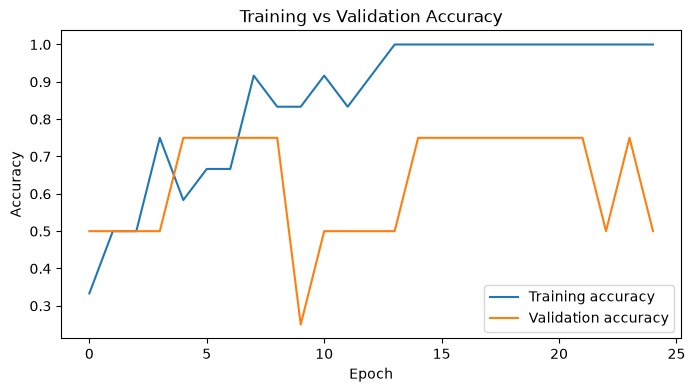

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

## Predict on New Sentences

The function applies the same tokenizer and vocabulary. Words unseen during training use the unknown-token ID.

In [10]:
def predict_sentiment(text):
    sequence = np.array([encode_and_pad(text)], dtype=np.int32)
    positive_probability = float(model.predict(sequence, verbose=0)[0][0])
    label = "positive" if positive_probability >= 0.5 else "negative"
    return {
        "text": text,
        "predicted_label": label,
        "positive_probability": round(positive_probability, 3)
    }

for sample in ["The movie was wonderful", "The film was awful", "I enjoyed this story"]:
    print(predict_sentiment(sample))

{'text': 'The movie was wonderful', 'predicted_label': 'positive', 'positive_probability': 0.905}
{'text': 'The film was awful', 'predicted_label': 'negative', 'positive_probability': 0.035}
{'text': 'I enjoyed this story', 'predicted_label': 'positive', 'positive_probability': 0.963}
